# Социальные сети, сон и ментальное здоровье студентов

Этот notebook объединяет визуальный анализ на Pandas/Seaborn и SQL-анализ на SQLite.

**Что внутри:**
- загрузка и быстрая проверка данных;
- визуализация ключевых взаимосвязей;
- создание локальной SQL-таблицы;
- SQL-задачи с таблицами и графиками.

## 1. Импорт библиотек и настройки

In [1]:
from pathlib import Path
import os
import sqlite3

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT_ROOT / '.matplotlib_cache'))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
DB_PATH = PROJECT_ROOT / 'data' / 'processed' / 'student_mental_health.sqlite'

COLORS = {
    'green': '#197278',
    'dark_green': '#283d3b',
    'brick': '#b85b4b',
    'sage': '#8aa899',
    'beige': '#f6f4ef',
    'panel': '#fffdf8',
}

sns.set_theme(
    style='whitegrid',
    rc={
        'figure.facecolor': COLORS['beige'],
        'axes.facecolor': COLORS['panel'],
        'grid.color': '#d9ded7',
        'axes.edgecolor': '#d9ded7',
    },
)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

## 2. Загрузка и подготовка датасета

In [2]:
csv_files = sorted(RAW_DIR.glob('*.csv'))
if not csv_files:
    raise FileNotFoundError('CSV не найден. Сначала запустите scripts/download_data.py')

csv_path = csv_files[0]
df = pd.read_csv(csv_path)
df.columns = [column.strip().lower() for column in df.columns]

numeric_columns = [
    'age', 'avg_daily_usage_hours', 'daily_unlocks', 'study_hours',
    'physical_activity_hours', 'sleep_hours_per_night', 'mental_health_score',
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

print(f'Источник: {csv_path.name}')
print(f'Размер датасета: {df.shape[0]:,} строк x {df.shape[1]} колонок')
df.head()

Источник: Student Social Media And Mental Health Impact.csv
Размер датасета: 5,000 строк x 13 колонок


,age,gender,country,academic_level,most_used_platform,purpose_of_use,avg_daily_usage_hours,daily_unlocks,study_hours,physical_activity_hours,sleep_hours_per_night,stress_level,mental_health_score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.00,134,4.50,2.20,6.70,Medium,6.80
1,23,Female,Other,Graduate,LinkedIn,Education,1.60,73,7.00,2.40,8.60,Low,7.60
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.60,166,4.00,1.80,6.70,Medium,7.00
3,18,Male,Other,High School,Snapchat,Entertainment,7.00,220,1.00,1.70,5.40,Very High,5.30
4,24,Female,Other,Graduate,Facebook,Networking,7.50,237,1.00,1.10,5.00,Very High,4.40


In [3]:
summary = (
    df[numeric_columns]
    .describe()
    .T
    .rename(columns={
        'count': 'Количество', 'mean': 'Среднее', 'std': 'Ст. отклонение',
        'min': 'Минимум', '25%': '25%', '50%': 'Медиана',
        '75%': '75%', 'max': 'Максимум',
    })
)
summary

,Количество,Среднее,Ст. отклонение,Минимум,25%,Медиана,75%,Максимум
age,"5,000.00",20.82,1.74,18.00,19.00,21.00,22.00,24.00
avg_daily_usage_hours,"5,000.00",5.08,1.65,1.00,3.80,5.00,6.30,8.80
daily_unlocks,"5,000.00",171.45,42.86,62.00,140.00,171.00,204.00,273.00
study_hours,"5,000.00",3.01,1.64,0.30,1.50,2.80,4.20,8.30
physical_activity_hours,"5,000.00",1.75,0.67,-0.40,1.30,1.70,2.20,4.10
sleep_hours_per_night,"5,000.00",6.63,1.22,3.60,5.60,6.60,7.50,9.90
mental_health_score,"5,000.00",6.23,1.28,3.60,5.10,6.10,7.10,9.40


## 3. Визуальный анализ

Сначала посмотрим на распределение времени в соцсетях и связи с учебой, сном и ментальным здоровьем.

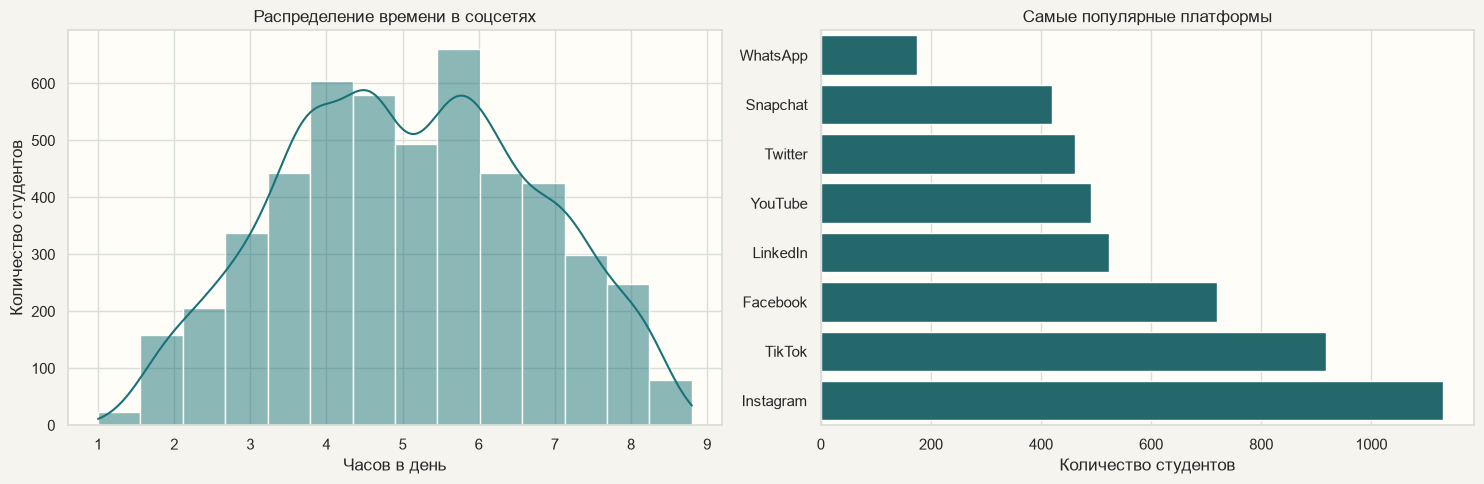

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df, x='avg_daily_usage_hours', bins=14, kde=True,
    color=COLORS['green'], edgecolor=COLORS['panel'], ax=axes[0],
)
axes[0].set_title('Распределение времени в соцсетях')
axes[0].set_xlabel('Часов в день')
axes[0].set_ylabel('Количество студентов')

platform_counts = df['most_used_platform'].value_counts().head(8).sort_values()
sns.barplot(
    x=platform_counts.values, y=platform_counts.index,
    color=COLORS['green'], ax=axes[1],
)
axes[1].set_title('Самые популярные платформы')
axes[1].set_xlabel('Количество студентов')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

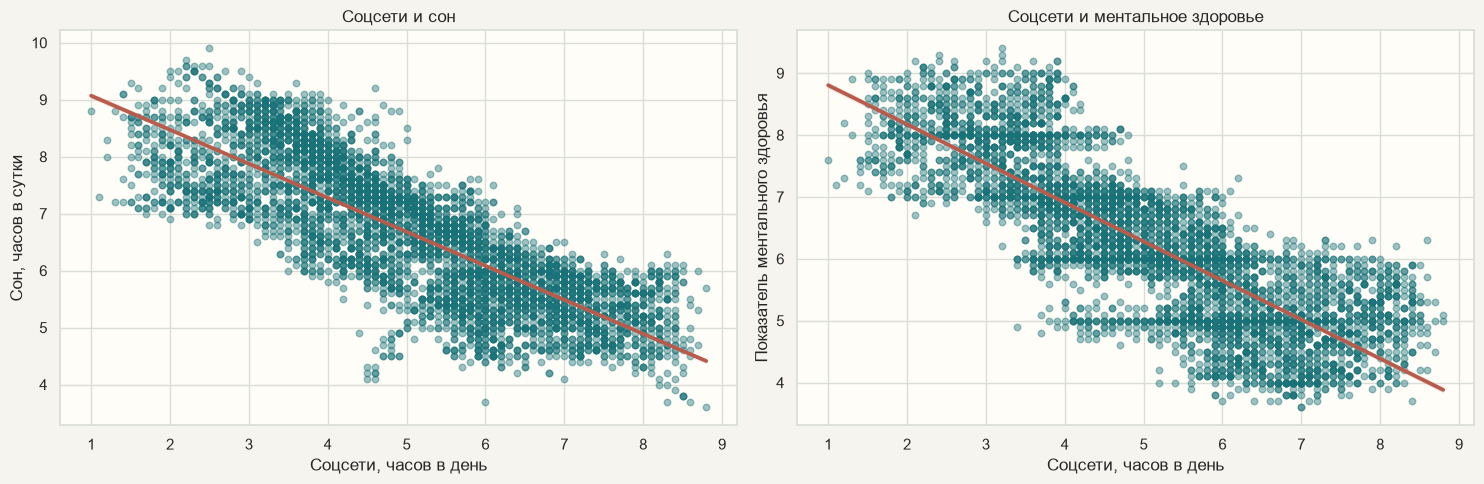

Корреляция: соцсети и сон = -0.808
Корреляция: соцсети и ментальное здоровье = -0.816


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.regplot(
    data=df, x='avg_daily_usage_hours', y='sleep_hours_per_night',
    scatter_kws={'alpha': 0.42, 's': 22, 'color': COLORS['green']},
    line_kws={'color': COLORS['brick'], 'linewidth': 2.7},
    ax=axes[0],
)
axes[0].set_title('Соцсети и сон')
axes[0].set_xlabel('Соцсети, часов в день')
axes[0].set_ylabel('Сон, часов в сутки')

sns.regplot(
    data=df, x='avg_daily_usage_hours', y='mental_health_score',
    scatter_kws={'alpha': 0.42, 's': 22, 'color': COLORS['green']},
    line_kws={'color': COLORS['brick'], 'linewidth': 2.7},
    ax=axes[1],
)
axes[1].set_title('Соцсети и ментальное здоровье')
axes[1].set_xlabel('Соцсети, часов в день')
axes[1].set_ylabel('Показатель ментального здоровья')

plt.tight_layout()
plt.show()

print('Корреляция: соцсети и сон =', round(df['avg_daily_usage_hours'].corr(df['sleep_hours_per_night']), 3))
print('Корреляция: соцсети и ментальное здоровье =', round(df['avg_daily_usage_hours'].corr(df['mental_health_score']), 3))

## 4. Создание SQL-базы

Загружаем DataFrame в SQLite. База сохраняется локально в `data/processed/student_mental_health.sqlite`, а таблица называется `student_social_media`.

In [6]:
DB_PATH.parent.mkdir(parents=True, exist_ok=True)
connection = sqlite3.connect(DB_PATH)
df.to_sql('student_social_media', connection, if_exists='replace', index=False)

schema = pd.read_sql_query('PRAGMA table_info(student_social_media);', connection)
print(f'База создана: {DB_PATH.name}')
schema[['name', 'type']].rename(columns={'name': 'Колонка', 'type': 'SQL-тип'})

База создана: student_mental_health.sqlite


,Колонка,SQL-тип
0,age,INTEGER
1,gender,TEXT
2,country,TEXT
3,academic_level,TEXT
4,most_used_platform,TEXT
5,purpose_of_use,TEXT
6,avg_daily_usage_hours,REAL
7,daily_unlocks,INTEGER
8,study_hours,REAL
9,physical_activity_hours,REAL


## 5. SQL-задача 1: средние показатели по уровню стресса

**Вопрос:** как меняются время в соцсетях, сон и показатель ментального здоровья при разных уровнях стресса?

In [7]:
sql_stress = '''
SELECT
    stress_level AS 'Уровень стресса',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(avg_daily_usage_hours), 2) AS 'Соцсети, ч/день',
    ROUND(AVG(sleep_hours_per_night), 2) AS 'Сон, ч/сутки',
    ROUND(AVG(mental_health_score), 2) AS 'Ментальное здоровье'
FROM student_social_media
GROUP BY stress_level
ORDER BY CASE stress_level
    WHEN 'Low' THEN 1
    WHEN 'Medium' THEN 2
    WHEN 'High' THEN 3
    WHEN 'Very High' THEN 4
END;
'''
stress_sql = pd.read_sql_query(sql_stress, connection)
stress_sql

,Уровень стресса,Студентов,"Соцсети, ч/день","Сон, ч/сутки",Ментальное здоровье
0,Low,644,2.78,8.16,7.84
1,Medium,1295,3.86,7.57,7.14
2,High,1440,5.19,6.45,6.03
3,Very High,1621,6.87,5.44,5.05


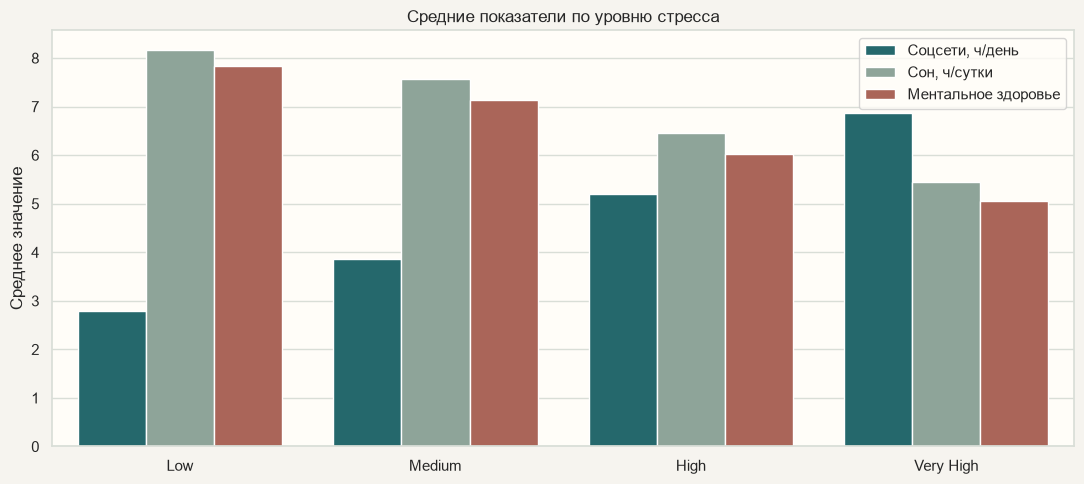

In [8]:
plot_stress = stress_sql.melt(
    id_vars='Уровень стресса',
    value_vars=['Соцсети, ч/день', 'Сон, ч/сутки', 'Ментальное здоровье'],
    var_name='Показатель', value_name='Среднее значение',
)
plt.figure(figsize=(11, 5))
sns.barplot(
    data=plot_stress, x='Уровень стресса', y='Среднее значение', hue='Показатель',
    palette=[COLORS['green'], COLORS['sage'], COLORS['brick']],
)
plt.title('Средние показатели по уровню стресса')
plt.xlabel('')
plt.ylabel('Среднее значение')
plt.legend(title='')
plt.tight_layout()
plt.show()

## 6. SQL-задача 2: платформы с самым высоким средним временем использования

**Вопрос:** какие платформы связаны с наибольшим средним количеством часов в соцсетях?

In [9]:
sql_platforms = '''
SELECT
    most_used_platform AS 'Платформа',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(avg_daily_usage_hours), 2) AS 'Среднее время, ч/день',
    ROUND(AVG(mental_health_score), 2) AS 'Среднее ментальное здоровье'
FROM student_social_media
GROUP BY most_used_platform
HAVING COUNT(*) >= 30
ORDER BY AVG(avg_daily_usage_hours) DESC
LIMIT 10;
'''
platform_sql = pd.read_sql_query(sql_platforms, connection)
platform_sql

,Платформа,Студентов,"Среднее время, ч/день",Среднее ментальное здоровье
0,WhatsApp,175,6.43,5.58
1,TikTok,918,5.26,5.99
2,Snapchat,420,5.25,6.12
3,Twitter,462,5.16,6.35
4,YouTube,491,5.15,6.22
5,WeChat,36,4.96,6.49
6,Facebook,719,4.93,6.40
7,Instagram,1130,4.92,6.19
8,LinkedIn,523,4.83,6.48
9,KakaoTalk,36,4.81,5.98


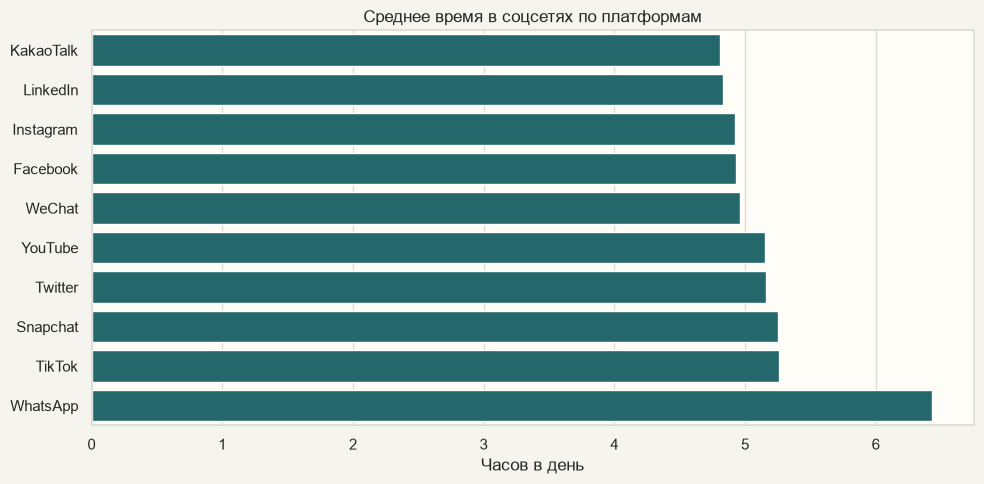

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=platform_sql.sort_values('Среднее время, ч/день'),
    x='Среднее время, ч/день', y='Платформа', color=COLORS['green'],
)
plt.title('Среднее время в соцсетях по платформам')
plt.xlabel('Часов в день')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 7. SQL-задача 3: группы по времени в соцсетях

**Вопрос:** чем отличаются студенты с низким, средним и высоким временем в соцсетях?

In [11]:
sql_usage_groups = '''
WITH grouped AS (
    SELECT
        CASE
            WHEN avg_daily_usage_hours < 3 THEN 'До 3 часов'
            WHEN avg_daily_usage_hours < 6 THEN 'От 3 до 6 часов'
            ELSE '6+ часов'
        END AS usage_group,
        sleep_hours_per_night,
        study_hours,
        mental_health_score
    FROM student_social_media
)
SELECT
    usage_group AS 'Группа использования',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(sleep_hours_per_night), 2) AS 'Сон, ч/сутки',
    ROUND(AVG(study_hours), 2) AS 'Учеба, ч/день',
    ROUND(AVG(mental_health_score), 2) AS 'Ментальное здоровье'
FROM grouped
GROUP BY usage_group
ORDER BY CASE usage_group
    WHEN 'До 3 часов' THEN 1
    WHEN 'От 3 до 6 часов' THEN 2
    WHEN '6+ часов' THEN 3
END;
'''
usage_groups_sql = pd.read_sql_query(sql_usage_groups, connection)
usage_groups_sql

,Группа использования,Студентов,"Сон, ч/сутки","Учеба, ч/день",Ментальное здоровье
0,До 3 часов,537,8.02,5.64,8.01
1,От 3 до 6 часов,2867,7.03,3.42,6.58
2,6+ часов,1596,5.46,1.39,5.00


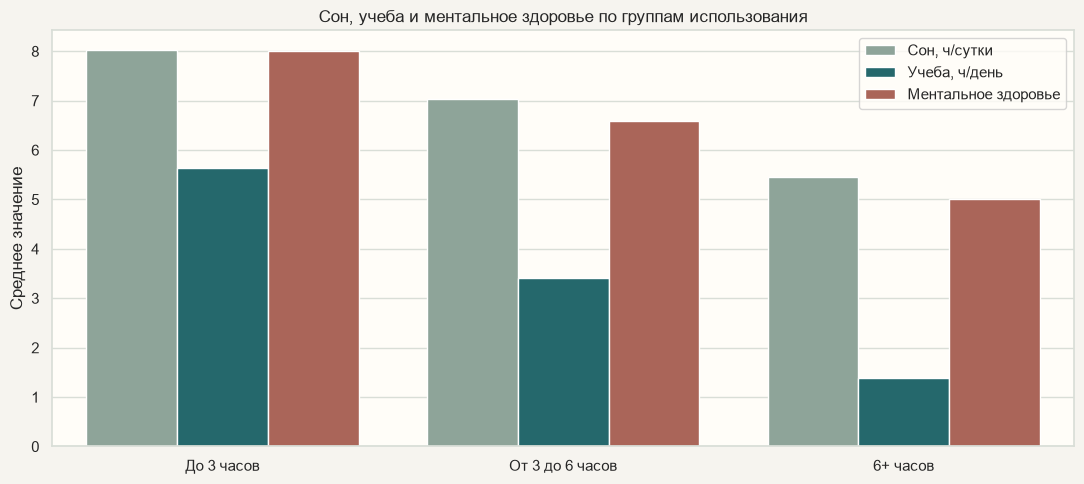

In [12]:
usage_long = usage_groups_sql.melt(
    id_vars='Группа использования',
    value_vars=['Сон, ч/сутки', 'Учеба, ч/день', 'Ментальное здоровье'],
    var_name='Показатель', value_name='Среднее значение',
)
plt.figure(figsize=(11, 5))
sns.barplot(
    data=usage_long, x='Группа использования', y='Среднее значение', hue='Показатель',
    palette=[COLORS['sage'], COLORS['green'], COLORS['brick']],
)
plt.title('Сон, учеба и ментальное здоровье по группам использования')
plt.xlabel('')
plt.ylabel('Среднее значение')
plt.legend(title='')
plt.tight_layout()
plt.show()

## 8. SQL-задача 4: страны с наивысшим средним показателем ментального здоровья

**Вопрос:** в каких странах показатель ментального здоровья выше при достаточном размере выборки?

In [13]:
sql_countries = '''
SELECT
    country AS 'Страна',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(mental_health_score), 2) AS 'Ментальное здоровье',
    ROUND(AVG(sleep_hours_per_night), 2) AS 'Сон, ч/сутки'
FROM student_social_media
GROUP BY country
HAVING COUNT(*) >= 100
ORDER BY AVG(mental_health_score) DESC
LIMIT 10;
'''
countries_sql = pd.read_sql_query(sql_countries, connection)
countries_sql

,Страна,Студентов,Ментальное здоровье,"Сон, ч/сутки"
0,Germany,136,6.65,6.88
1,Australia,198,6.40,6.75
2,Other,1880,6.25,6.41
3,Canada,230,6.24,6.96
4,India,389,6.01,6.35
5,USA,355,5.80,6.13
6,UK,185,5.77,6.34


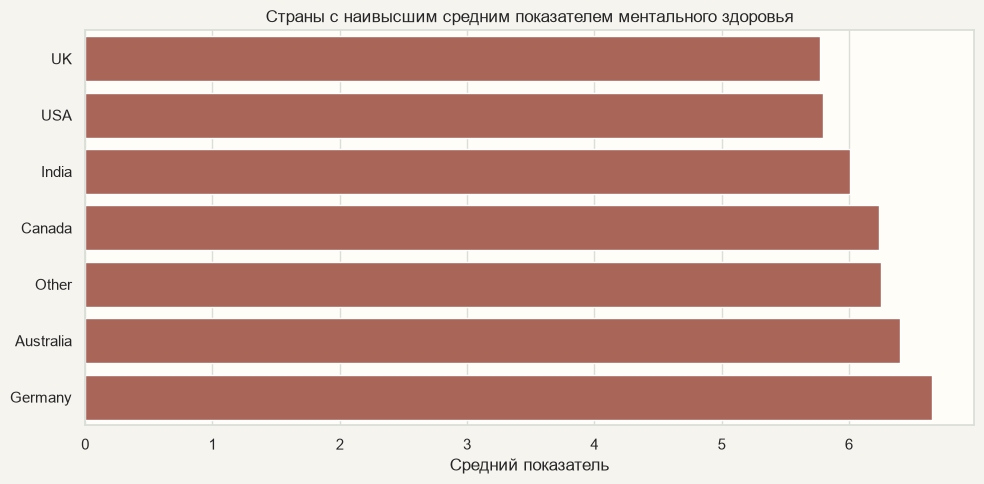

In [14]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=countries_sql.sort_values('Ментальное здоровье'),
    x='Ментальное здоровье', y='Страна', color=COLORS['brick'],
)
plt.title('Страны с наивысшим средним показателем ментального здоровья')
plt.xlabel('Средний показатель')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 9. SQL-задача 5: проверка данных

**Вопрос:** есть ли пропуски в полях, которые мы используем для анализа?

In [15]:
sql_quality = '''
SELECT
    COUNT(*) AS 'Всего строк',
    SUM(CASE WHEN avg_daily_usage_hours IS NULL THEN 1 ELSE 0 END) AS 'Пропуски: соцсети',
    SUM(CASE WHEN sleep_hours_per_night IS NULL THEN 1 ELSE 0 END) AS 'Пропуски: сон',
    SUM(CASE WHEN mental_health_score IS NULL THEN 1 ELSE 0 END) AS 'Пропуски: ментальное здоровье',
    SUM(CASE WHEN stress_level IS NULL THEN 1 ELSE 0 END) AS 'Пропуски: стресс'
FROM student_social_media;
'''
pd.read_sql_query(sql_quality, connection)

,Всего строк,Пропуски: соцсети,Пропуски: сон,Пропуски: ментальное здоровье,Пропуски: стресс
0,5000,0,0,0,0


## 10. SQL-задача 6: различия по полу

**Вопрос:** отличаются ли среднее время в соцсетях, сон и показатель ментального здоровья между группами по полу?

In [16]:
sql_gender = '''
SELECT
    gender AS 'Пол',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(avg_daily_usage_hours), 2) AS 'Соцсети, ч/день',
    ROUND(AVG(sleep_hours_per_night), 2) AS 'Сон, ч/сутки',
    ROUND(AVG(mental_health_score), 2) AS 'Ментальное здоровье'
FROM student_social_media
GROUP BY gender
ORDER BY COUNT(*) DESC;
'''
gender_sql = pd.read_sql_query(sql_gender, connection)
gender_sql

,Пол,Студентов,"Соцсети, ч/день","Сон, ч/сутки",Ментальное здоровье
0,Male,2635,5.03,6.66,6.27
1,Female,2365,5.13,6.61,6.19


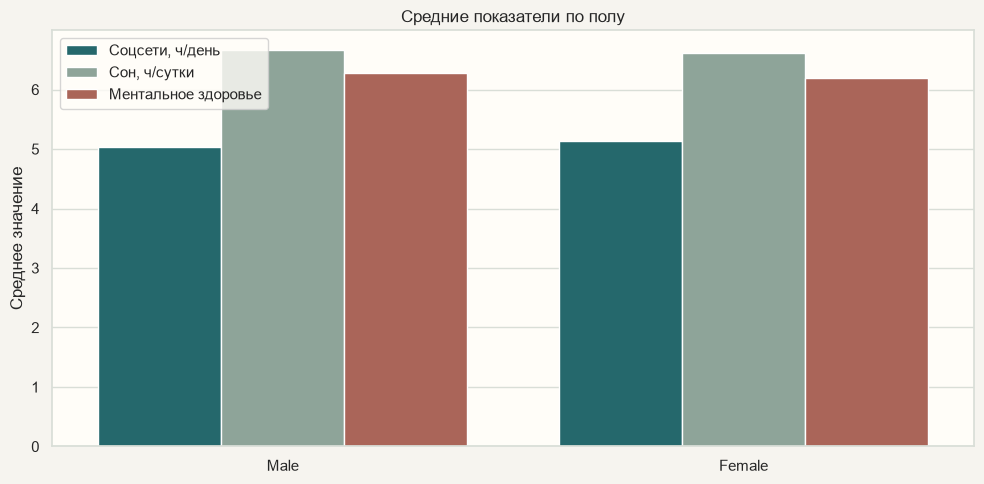

In [17]:
gender_long = gender_sql.melt(
    id_vars='Пол',
    value_vars=['Соцсети, ч/день', 'Сон, ч/сутки', 'Ментальное здоровье'],
    var_name='Показатель', value_name='Среднее значение',
)
plt.figure(figsize=(10, 5))
sns.barplot(
    data=gender_long, x='Пол', y='Среднее значение', hue='Показатель',
    palette=[COLORS['green'], COLORS['sage'], COLORS['brick']],
)
plt.title('Средние показатели по полу')
plt.xlabel('')
plt.ylabel('Среднее значение')
plt.legend(title='')
plt.tight_layout()
plt.show()

## 11. SQL-задача 7: цели использования и высокий стресс

**Вопрос:** при каких целях использования соцсетей доля студентов с высоким или очень высоким стрессом больше?

In [18]:
sql_purpose_stress = '''
SELECT
    purpose_of_use AS 'Цель использования',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(avg_daily_usage_hours), 2) AS 'Соцсети, ч/день',
    ROUND(100.0 * AVG(CASE
        WHEN stress_level IN ('High', 'Very High') THEN 1.0
        ELSE 0.0
    END), 1) AS 'Высокий стресс, %'
FROM student_social_media
GROUP BY purpose_of_use
ORDER BY `Высокий стресс, %` DESC;
'''
purpose_stress_sql = pd.read_sql_query(sql_purpose_stress, connection)
purpose_stress_sql

,Цель использования,Студентов,"Соцсети, ч/день","Высокий стресс, %"
0,Entertainment,2552,5.11,63.30
1,News,561,5.20,61.70
2,Education,1094,5.01,59.30
3,Networking,793,4.98,56.90


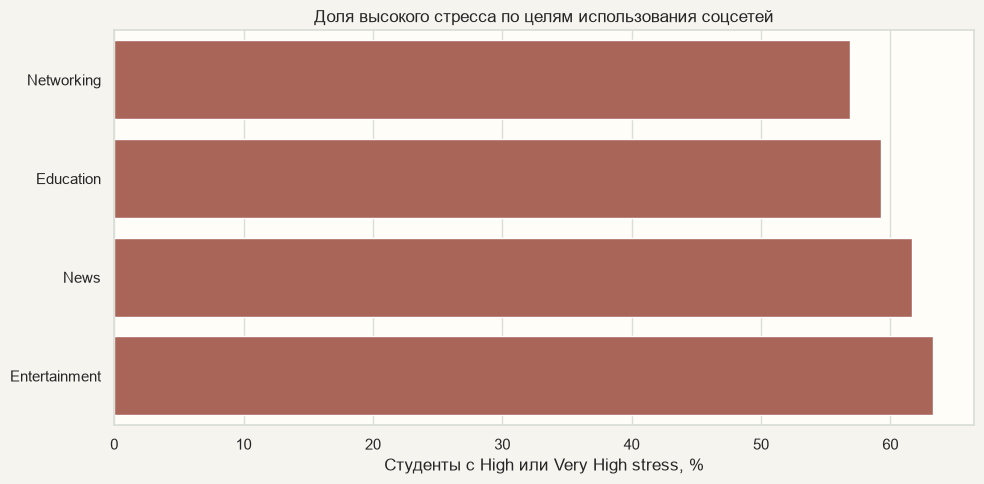

In [19]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=purpose_stress_sql.sort_values('Высокий стресс, %'),
    x='Высокий стресс, %', y='Цель использования', color=COLORS['brick'],
)
plt.title('Доля высокого стресса по целям использования соцсетей')
plt.xlabel('Студенты с High или Very High stress, %')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 12. SQL-задача 8: группы по числу разблокировок телефона

**Вопрос:** как различаются сон, учеба и ментальное здоровье у студентов с разной частотой разблокировок телефона?

In [20]:
sql_unlocks = '''
WITH grouped AS (
    SELECT
        CASE
            WHEN daily_unlocks < 120 THEN 'До 120'
            WHEN daily_unlocks < 200 THEN '120-199'
            ELSE '200+'
        END AS unlock_group,
        sleep_hours_per_night,
        study_hours,
        mental_health_score
    FROM student_social_media
)
SELECT
    unlock_group AS 'Разблокировок в день',
    COUNT(*) AS 'Студентов',
    ROUND(AVG(sleep_hours_per_night), 2) AS 'Сон, ч/сутки',
    ROUND(AVG(study_hours), 2) AS 'Учеба, ч/день',
    ROUND(AVG(mental_health_score), 2) AS 'Ментальное здоровье'
FROM grouped
GROUP BY unlock_group
ORDER BY CASE unlock_group
    WHEN 'До 120' THEN 1
    WHEN '120-199' THEN 2
    WHEN '200+' THEN 3
END;
'''
unlocks_sql = pd.read_sql_query(sql_unlocks, connection)
unlocks_sql

,Разблокировок в день,Студентов,"Сон, ч/сутки","Учеба, ч/день",Ментальное здоровье
0,До 120,592,7.97,5.50,7.94
1,120-199,3011,6.92,3.29,6.46
2,200+,1397,5.45,1.35,5.01


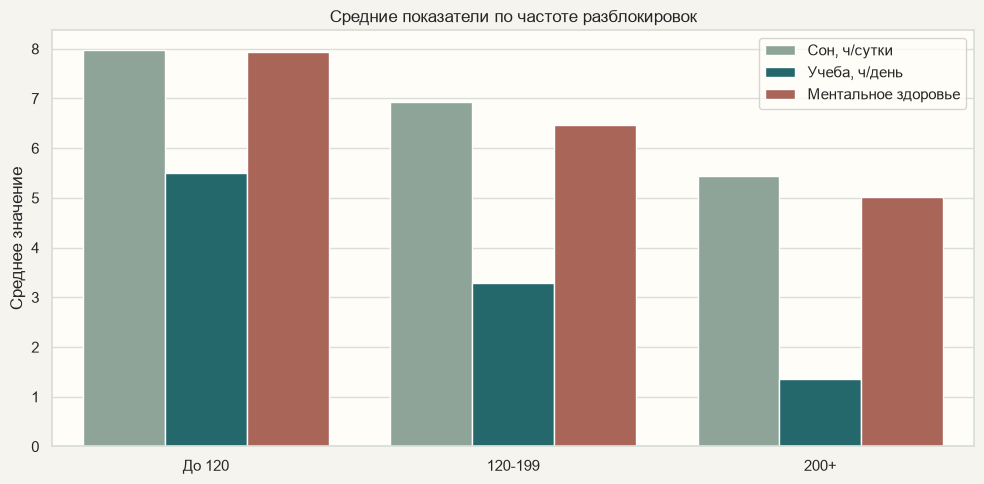

In [21]:
unlocks_long = unlocks_sql.melt(
    id_vars='Разблокировок в день',
    value_vars=['Сон, ч/сутки', 'Учеба, ч/день', 'Ментальное здоровье'],
    var_name='Показатель', value_name='Среднее значение',
)
plt.figure(figsize=(10, 5))
sns.barplot(
    data=unlocks_long, x='Разблокировок в день', y='Среднее значение', hue='Показатель',
    palette=[COLORS['sage'], COLORS['green'], COLORS['brick']],
)
plt.title('Средние показатели по частоте разблокировок')
plt.xlabel('')
plt.ylabel('Среднее значение')
plt.legend(title='')
plt.tight_layout()
plt.show()

## 13. Вывод

По датасету видна сильная отрицательная связь между ежедневным временем в социальных сетях, продолжительностью сна и показателем ментального здоровья. Это наблюдаемая корреляция: она описывает совместное изменение признаков, но не доказывает, что использование соцсетей является единственной причиной изменений сна или ментального здоровья.

После завершения работы закройте соединение с базой:

In [22]:
connection.close()